## 1. Load the data and set up

**Goal:** Find the best model for predicting late orders, with accuracy as the headline metric, and show what it costs to catch more late orders (fewer missed late orders means more false alarms).


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import optuna

In [2]:
folder = "../data/processed/"
train = pd.read_csv(folder + "train_features.csv", parse_dates=["order_date_dateorders"])
val = pd.read_csv(folder + "val_features.csv", parse_dates=["order_date_dateorders"])
test = pd.read_csv(folder + "test_features.csv", usecols=lambda column: column != "late_delivery_risk",
                   parse_dates=["order_date_dateorders"])
train = train.sort_values("order_date_dateorders").reset_index(drop=True)
KEYS = ["order_id", "order_date_dateorders", "late_delivery_risk"]
TEXT = ["type", "shipping_mode", "market", "order_region", "customer_segment", "hour_bucket",
        "mode_hour", "mode_weekday", "mode_region", "mode_size", "same_day_period"]
NUMERIC = ["order_hour", "order_day_of_week", "order_month", "is_weekend",
           "order_is_holiday_season", "same_day_after_cutoff", "order_country_freq",
           "order_state_freq", "order_city_freq", "order_total_sales", "items_in_order", "is_high_value"]

In [3]:
groups = {
    "shipping": ["shipping_mode", "same_day_after_cutoff"],
    "time": ["order_hour", "order_day_of_week", "order_month", "is_weekend", "order_is_holiday_season"],
    "place": ["order_country_freq", "order_state_freq", "order_city_freq"],
    "order size": ["order_total_sales", "items_in_order", "is_high_value"],
    "type and customer": ["type", "customer_segment"],
    "market and region": ["market", "order_region"],
    "combined ideas": ["mode_hour", "mode_weekday", "mode_region", "mode_size", "same_day_period"],
}

In [4]:
feature_cols = [c for c in train.columns if c not in KEYS and c != "hour_bucket"]
X_train, y_train = train[feature_cols], train["late_delivery_risk"]
X_val, y_val = val[feature_cols], val["late_delivery_risk"]
print("Train, validation, test shapes:", train.shape, val.shape, test.shape)
print(f"Late share: train {y_train.mean():.1%}; validation {y_val.mean():.1%}")
print("Feature columns:", feature_cols)

Train, validation, test shapes: (44028, 26) (9434, 26) (9435, 25)
Late share: train 57.3%; validation 57.0%
Feature columns: ['type', 'shipping_mode', 'market', 'order_region', 'customer_segment', 'mode_hour', 'mode_weekday', 'mode_region', 'mode_size', 'same_day_period', 'order_hour', 'order_day_of_week', 'order_month', 'is_weekend', 'order_is_holiday_season', 'same_day_after_cutoff', 'order_country_freq', 'order_state_freq', 'order_city_freq', 'order_total_sales', 'items_in_order', 'is_high_value']


In [5]:
def score(y, probability, cutoff=0.5):
    prediction = (np.asarray(probability) >= cutoff).astype(int)
    return {"accuracy": accuracy_score(y, prediction), "precision": precision_score(y, prediction, zero_division=0),
            "recall": recall_score(y, prediction, zero_division=0), "f1": f1_score(y, prediction, zero_division=0),
            "auc": roc_auc_score(y, probability), "late_missed": int(((np.asarray(y) == 1) & (prediction == 0)).sum()),
            "false_alarms": int(((np.asarray(y) == 0) & (prediction == 1)).sum())}

def make_pipeline(model, columns, scale=False):
    text_cols = [c for c in columns if c in TEXT]
    numeric_cols = [c for c in columns if c in NUMERIC]
    numeric_step = StandardScaler() if scale else "passthrough"
    prep = ColumnTransformer([("text", OneHotEncoder(handle_unknown="ignore"), text_cols),
                              ("numeric", numeric_step, numeric_cols)], remainder="drop",
                             verbose_feature_names_out=False)
    return Pipeline([("preprocess", prep), ("model", model)])

## 2. Testing Feature Groups

In [6]:
base = groups["shipping"] + groups["time"]
sets = {"shipping only": groups["shipping"], "base": base,
        "base + place": base + groups["place"], "base + order size": base + groups["order size"],
        "base + type and customer": base + groups["type and customer"],
        "base + market and region": base + groups["market and region"]}
for col in groups["combined ideas"]:
    sets["base + " + col] = base + [col]
sets["base + all combined ideas"] = base + groups["combined ideas"]
sets["all columns"] = feature_cols
lightgbm_settings = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=42, verbosity=-1)
feature_rows = []

In [7]:
for name, columns in sets.items():
    model = make_pipeline(LGBMClassifier(**lightgbm_settings), columns).fit(X_train[columns], y_train)
    train_p, val_p = model.predict_proba(X_train[columns])[:, 1], model.predict_proba(X_val[columns])[:, 1]
    feature_rows.append({"set": name, "columns": len(columns), "validation_accuracy": accuracy_score(y_val, val_p >= 0.5),
                         "validation_auc": roc_auc_score(y_val, val_p),
                         "train_minus_validation_auc": roc_auc_score(y_train, train_p) - roc_auc_score(y_val, val_p)})
feature_table = pd.DataFrame(feature_rows).set_index("set")
print("Keep rule: accuracy +0.005, or AUC +0.005 with accuracy no more than 0.002 lower than base.")
display(feature_table.round(3))

Keep rule: accuracy +0.005, or AUC +0.005 with accuracy no more than 0.002 lower than base.


,columns,validation_accuracy,validation_auc,train_minus_validation_auc
set,,,,
shipping only,2,0.726,0.775,-0.001
base,7,0.725,0.794,0.035
base + place,10,0.724,0.789,0.066
base + order size,10,0.724,0.776,0.080
base + type and customer,9,0.725,0.784,0.055
base + market and region,9,0.725,0.780,0.049
base + mode_hour,8,0.726,0.793,0.036
base + mode_weekday,8,0.726,0.790,0.037
base + mode_region,8,0.725,0.780,0.046


In [8]:
order_size_means = pd.DataFrame({name: frame[["items_in_order", "order_total_sales"]].mean()
                                    for name, frame in [("train", train), ("validation", val), ("test", test)]}).T
display(order_size_means.round(2))
base_row = feature_table.loc["base"]
kept = []
for name, row in feature_table.iterrows():
    if name in ["shipping only", "base"] or "order size" in name or "mode_size" in name:
        continue
    if row["validation_accuracy"] >= base_row["validation_accuracy"] + 0.005 or (
        row["validation_auc"] >= base_row["validation_auc"] + 0.005 and row["validation_accuracy"] >= base_row["validation_accuracy"] - 0.002):
        kept.extend(sets[name])
final_cols = list(dict.fromkeys(base + kept))
final_cols = [c for c in final_cols if c not in groups["order size"] and c != "mode_size"]
print("Kept groups after the rule and order-size exclusion:", list(dict.fromkeys(kept)))
print("final_cols:", final_cols)

,items_in_order,order_total_sales
train,3.00,591.90
validation,2.99,614.22
test,1.31,356.10


Kept groups after the rule and order-size exclusion: []
final_cols: ['shipping_mode', 'same_day_after_cutoff', 'order_hour', 'order_day_of_week', 'order_month', 'is_weekend', 'order_is_holiday_season']


Order-size features are left out because the test period has much smaller orders (1.31 items per order against about 3.00 in train and validation). This decision used the test features only. Test labels were not loaded until the final comparison.

## 3. Baseline: logistic regression



In [9]:
models = {}
logistic = make_pipeline(LogisticRegression(max_iter=1000, random_state=42), final_cols, scale=True)
logistic.fit(X_train[final_cols], y_train)
models["Logistic regression"] = logistic
logit_rows = []
for split, X, y in [("train", X_train, y_train), ("validation", X_val, y_val)]:
    probability = logistic.predict_proba(X[final_cols])[:, 1]
    logit_rows.append({"split": split, "accuracy": accuracy_score(y, probability >= 0.5), "auc": roc_auc_score(y, probability)})
display(pd.DataFrame(logit_rows).set_index("split").round(3))

,accuracy,auc
split,,
train,0.722,0.776
validation,0.726,0.776


logistic regression reaches 0.722 accuracy and 0.776 AUC on train. On validation it gets 0.726 accuracy and the same 0.776 AUC.

## 4. Train the other models



In [10]:
candidates = {
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1),
    "LightGBM": LGBMClassifier(**lightgbm_settings),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42, eval_metric="logloss", n_jobs=-1),
    "CatBoost": CatBoostClassifier(iterations=300, learning_rate=0.05, depth=6, random_seed=42, verbose=0),
}
models.update({name: make_pipeline(estimator, final_cols).fit(X_train[final_cols], y_train)
               for name, estimator in candidates.items()})
model_rows = []
for name, pipe in candidates.items():
    for split, X, y in [("train", X_train, y_train), ("validation", X_val, y_val)]:
        probability = models[name].predict_proba(X[final_cols])[:, 1]
        model_rows.append({"model": name, "split": split, "accuracy": accuracy_score(y, probability >= 0.5),
                           "auc": roc_auc_score(y, probability)})
display(pd.DataFrame(model_rows).pivot(index="model", columns="split").round(3))

accuracy               auc           
split            train validation  train validation
model                                              
CatBoost         0.722      0.726  0.797      0.778
LightGBM         0.727      0.725  0.829      0.794
Random Forest    0.726      0.725  0.830      0.789
XGBoost          0.725      0.725  0.810      0.779

In [11]:
light_val = models["LightGBM"].predict_proba(X_val[final_cols])[:, 1]
val_detail = val[["shipping_mode", "late_delivery_risk"]].copy()
val_detail["prediction"] = (light_val >= 0.5).astype(int)
mode_table = val_detail.groupby("shipping_mode").agg(orders=("late_delivery_risk", "size"),
    late_share=("late_delivery_risk", "mean"), accuracy=("prediction", lambda p: np.mean(p == val_detail.loc[p.index, "late_delivery_risk"])))
display(mode_table.round(3))

,orders,late_share,accuracy
shipping_mode,,,
First Class,1432,1.000,1.000
Same Day,528,0.527,1.000
Second Class,1844,0.793,0.793
Standard Class,5630,0.392,0.607


First Class and Same Day have 100% validation accuracy, while Second Class reaches 79.3% and Standard Class 60.7%. The model struggles most with Standard Class orders, followed by Second Class. In Standard Class, the actual late-delivery rate across the ten risk groups ranges from 31.6% to 48.8%. No group exceeds 50%, so late deliveries do not make up the majority in any of these groups.

## 5. Tuning

Optuna tries 25 settings for each model, ranked by mean fold accuracy, and reports mean AUC too.

In [13]:
def tune_model(kind):
    def objective(trial):
        params = {"n_estimators": trial.suggest_int("n_estimators", 100, 600),
                  "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True), "max_depth": trial.suggest_int("max_depth", 3, 10),
                  "subsample": trial.suggest_float("subsample", 0.6, 1.0), "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
                  "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 2.0), "reg_lambda": trial.suggest_float("reg_lambda", 0.0, 5.0)}
        params.update({"num_leaves": trial.suggest_int("num_leaves", 8, 64), "min_child_samples": trial.suggest_int("min_child_samples", 10, 100)} if kind == "LightGBM" else {"min_child_weight": trial.suggest_float("min_child_weight", 1.0, 10.0)})
        accuracy_folds, auc_folds = [], []
        for train_idx, valid_idx in TimeSeriesSplit(n_splits=4).split(X_train):
            estimator = LGBMClassifier(**params, random_state=42, verbosity=-1, subsample_freq=1) if kind == "LightGBM" else XGBClassifier(**params, random_state=42, eval_metric="logloss", n_jobs=-1)
            pipe = make_pipeline(estimator, final_cols).fit(X_train.iloc[train_idx][final_cols], y_train.iloc[train_idx])
            probability = pipe.predict_proba(X_train.iloc[valid_idx][final_cols])[:, 1]
            accuracy_folds.append(accuracy_score(y_train.iloc[valid_idx], probability >= 0.5)); auc_folds.append(roc_auc_score(y_train.iloc[valid_idx], probability))
        trial.set_user_attr("mean_auc", float(np.mean(auc_folds))); return float(np.mean(accuracy_folds))
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42)); study.optimize(objective, n_trials=25); return study

In [14]:
print("Tuning plan: 25 trials per model; 4 forward-time folds; seed 42; optimize mean accuracy and report mean AUC.")
optuna.logging.set_verbosity(optuna.logging.WARNING)
studies = {kind: tune_model(kind) for kind in ["LightGBM", "XGBoost"]}
fold_table = pd.DataFrame([{"model": name, "mean_fold_accuracy": study.best_value,
                           "mean_fold_auc": study.best_trial.user_attrs["mean_auc"]}
                          for name, study in studies.items()]).set_index("model")
display(fold_table.round(4))

Tuning plan: 25 trials per model; 4 forward-time folds; seed 42; optimize mean accuracy and report mean AUC.


,mean_fold_accuracy,mean_fold_auc
model,,
LightGBM,0.7219,0.7760
XGBoost,0.7219,0.7756


In [15]:
tuned_models = {}
for name, study in studies.items():
    estimator = LGBMClassifier(**study.best_params, random_state=42, verbosity=-1, subsample_freq=1) if name == "LightGBM" else XGBClassifier(**study.best_params, random_state=42, eval_metric="logloss", n_jobs=-1)
    tuned_models[name] = make_pipeline(estimator, final_cols).fit(X_train[final_cols], y_train)
    models[name + " tuned"] = tuned_models[name]
delta_rows = []
for name in ["LightGBM", "XGBoost"]:
    base_p = models[name].predict_proba(X_val[final_cols])[:, 1]
    tuned_p = tuned_models[name].predict_proba(X_val[final_cols])[:, 1]
    delta_rows.append({"model": name, "accuracy_delta": accuracy_score(y_val, tuned_p >= 0.5) - accuracy_score(y_val, base_p >= 0.5),
                       "auc_delta": roc_auc_score(y_val, tuned_p) - roc_auc_score(y_val, base_p)})
delta_table = pd.DataFrame(delta_rows).set_index("model")
display(delta_table.round(4))
print("Tuning helped validation accuracy by at least 0.003:", bool((delta_table["accuracy_delta"] >= 0.003).any()))

,accuracy_delta,auc_delta
model,,
LightGBM,0.0003,-0.0165
XGBoost,0.0001,-0.0007


Tuning helped validation accuracy by at least 0.003: False


Both tuned models ended up with a mean cross-validation accuracy of 0.7219. On validation data, LightGBM's accuracy improved by just 0.0003, while its AUC fell by 0.0165. XGBoost showed almost no change in accuracy (+0.0001) and a small drop in AUC (-0.0007). Neither model gained the minimum 0.003 accuracy improvement, so tuning wasn't worth keeping.

## 6. Pick the best model



In [16]:
validation_rows = []
for name, pipe in models.items():
    probability = pipe.predict_proba(X_val[final_cols])[:, 1]
    validation_rows.append({"model": name, "validation_accuracy": accuracy_score(y_val, probability >= 0.5),
                            "validation_auc": roc_auc_score(y_val, probability)})
validation_table = pd.DataFrame(validation_rows).set_index("model").sort_values(
    ["validation_accuracy", "validation_auc"], ascending=False)
display(validation_table.round(3))

,validation_accuracy,validation_auc
model,,
XGBoost tuned,0.726,0.778
CatBoost,0.726,0.778
LightGBM tuned,0.726,0.778
Logistic regression,0.726,0.776
Random Forest,0.725,0.789
XGBoost,0.725,0.779
LightGBM,0.725,0.794


In [31]:
# Sanity check: accuracy this far above the others would point to leakage
print("Best validation accuracy:", round(validation_table["validation_accuracy"].max(), 3))

Best validation accuracy: 0.726


In [18]:
print("Selection rule: highest accuracy; within 0.003 use highest AUC; if tied, prefer LightGBM.")
top_accuracy = validation_table["validation_accuracy"].max()
shortlist = validation_table[validation_table["validation_accuracy"] >= top_accuracy - 0.003]
ties = shortlist[shortlist["validation_auc"] == shortlist["validation_auc"].max()].index.tolist()
chosen_name = next((name for name in ties if "LightGBM" in name), ties[0])
chosen_model = models[chosen_name]
print("Chosen model:", chosen_name)
print("Validation accuracy difference from logistic regression:", round(validation_table.loc[chosen_name, "validation_accuracy"] - validation_table.loc["Logistic regression", "validation_accuracy"], 4))

Selection rule: highest accuracy; within 0.003 use highest AUC; if tied, prefer LightGBM.
Chosen model: LightGBM
Validation accuracy difference from logistic regression: -0.0003


All models have nearly the same validation accuracy, with differences of less than 0.001. LightGBM has the highest AUC at 0.794, so it is selected as the final model. However, its accuracy is 0.0003 lower than logistic regression, which is well within the 0.003 margin. In terms of accuracy, logistic regression performs just as well.

## 7. Choosing a Classification Cutoff

Lowering the cutoff catches more late orders but also increases false alarms and can reduce overall accuracy. The 75% catch rate is a target chosen for this analysis, not something derived from the data.

In [19]:
chosen_val_p = chosen_model.predict_proba(X_val[final_cols])[:, 1]
cutoff_rows = []
for cutoff in np.round(np.arange(0.30, 0.701, 0.05), 2):
    result = score(y_val, chosen_val_p, cutoff)
    cutoff_rows.append({"cutoff": cutoff, "accuracy": result["accuracy"], "late_missed": result["late_missed"],
                        "false_alarms": result["false_alarms"], "late_caught_share": result["recall"],
                        "precision": result["precision"], "orders_called_late_share": (chosen_val_p >= cutoff).mean()})
cutoff_table = pd.DataFrame(cutoff_rows).set_index("cutoff")
display(cutoff_table.round(3))

,accuracy,late_missed,false_alarms,late_caught_share,precision,orders_called_late_share
cutoff,,,,,,
0.30,0.600,12,3766,0.998,0.588,0.968
0.35,0.608,94,3603,0.983,0.595,0.942
0.40,0.693,1122,1776,0.791,0.706,0.639
0.45,0.726,2031,554,0.622,0.858,0.414
0.50,0.725,2170,422,0.597,0.884,0.385
0.55,0.726,2207,382,0.590,0.893,0.377
0.60,0.725,2208,382,0.590,0.892,0.377
0.65,0.725,2215,381,0.588,0.893,0.376
0.70,0.724,2229,379,0.586,0.893,0.374


In [20]:
max_accuracy = cutoff_table["accuracy"].max()
normal_cutoff = 0.5 if cutoff_table.loc[0.5, "accuracy"] >= max_accuracy - 0.002 else cutoff_table["accuracy"].idxmax()
eligible = cutoff_table[cutoff_table["late_caught_share"] >= 0.75]
catch_cutoff = eligible.index.max() if len(eligible) else None
print("Normal cutoff:", normal_cutoff)
print("Catch-more cutoff:", catch_cutoff)
print("75% catch target is an assumption, not data.")

Normal cutoff: 0.5
Catch-more cutoff: 0.4
75% catch target is an assumption, not data.


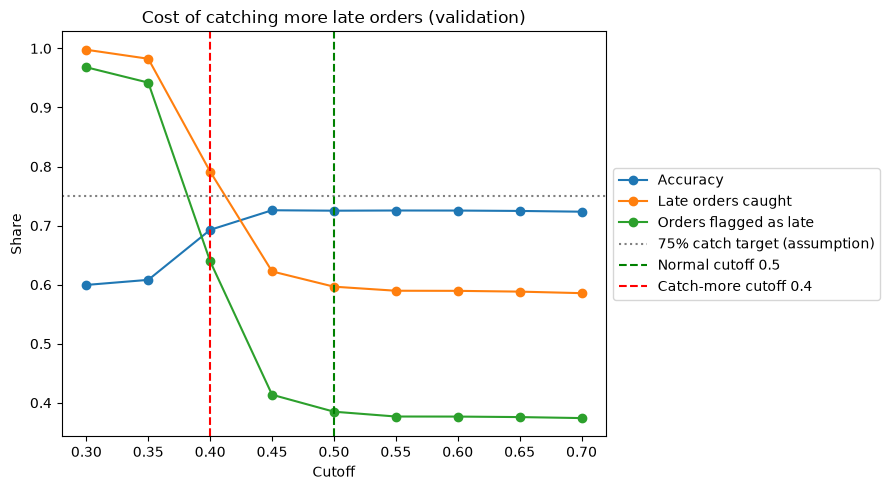

In [29]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(cutoff_table.index, cutoff_table["accuracy"], marker="o", label="Accuracy")
ax.plot(cutoff_table.index, cutoff_table["late_caught_share"], marker="o", label="Late orders caught")
ax.plot(cutoff_table.index, cutoff_table["orders_called_late_share"], marker="o", label="Orders flagged as late")
ax.axhline(0.75, color="grey", linestyle=":", label="75% catch target (assumption)")
ax.axvline(normal_cutoff, color="green", linestyle="--", label=f"Normal cutoff {normal_cutoff}")
ax.axvline(catch_cutoff, color="red", linestyle="--", label=f"Catch-more cutoff {catch_cutoff}")
ax.set_xlabel("Cutoff")
ax.set_ylabel("Share")
ax.set_title("Cost of catching more late orders (validation)")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

At the default 0.50 cutoff, accuracy is 0.725, almost the highest observed (0.726). Lowering it to 0.40 catches 79% of late orders, but misses 1,122 and flags another 1,776 on-time orders as late. Accuracy drops to 0.693, and 64% of all orders are flagged as late. At 0.35 and 0.30, the model flags 94% and 97% of orders as late, making those cutoffs less practical.

## 8. Decision



In [21]:
print("Chosen model:", chosen_name)
print("final_cols:", final_cols)
print("Normal cutoff:", normal_cutoff)
print("Catch-more cutoff:", catch_cutoff)

Chosen model: LightGBM
final_cols: ['shipping_mode', 'same_day_after_cutoff', 'order_hour', 'order_day_of_week', 'order_month', 'is_weekend', 'order_is_holiday_season']
Normal cutoff: 0.5
Catch-more cutoff: 0.4


## 9. Compare every model on train, validation and test

How do all models score on the three splits at the standard 0.50 cutoff?

In [22]:
test = pd.read_csv(folder + "test_features.csv", parse_dates=["order_date_dateorders"])
X_test, y_test = test[feature_cols], test["late_delivery_risk"]
split_data = [("train", X_train, y_train), ("validation", X_val, y_val), ("test", X_test, y_test)]
all_scores, comparison_rows = {}, []
for name, pipe in models.items():
    all_scores[name] = {}
    for split, X, y in split_data:
        probability = pipe.predict_proba(X[final_cols])[:, 1]
        all_scores[name][split] = probability
        row = {"model": name, "split": split, "accuracy": accuracy_score(y, probability >= 0.5), "auc": roc_auc_score(y, probability)}
        if split == "test":
            row["precision"] = precision_score(y, probability >= 0.5, zero_division=0)
            row["late_caught_recall"] = recall_score(y, probability >= 0.5, zero_division=0)
        comparison_rows.append(row)

In [23]:
comparison = pd.DataFrame(comparison_rows)
display(comparison.set_index(["model", "split"]).round(3))
auc_wide = comparison.pivot(index="model", columns="split", values="auc")
auc_wide["train_to_test_auc_drop"] = auc_wide["train"] - auc_wide["test"]
display(auc_wide[["train_to_test_auc_drop"]].round(3))

accuracy    auc  precision  late_caught_recall
model               split                                                     
Logistic regression train          0.722  0.776        NaN                 NaN
                    validation     0.726  0.776        NaN                 NaN
                    test           0.724  0.775      0.897               0.587
Random Forest       train          0.726  0.830        NaN                 NaN
                    validation     0.725  0.789        NaN                 NaN
                    test           0.723  0.788      0.882               0.598
LightGBM            train          0.727  0.829        NaN                 NaN
                    validation     0.725  0.794        NaN                 NaN
                    test           0.724  0.800      0.883               0.601
XGBoost             train          0.725  0.810        NaN                 NaN
                    validation     0.725  0.779        NaN                 NaN
                    test           0.725  0.789      0.887               0.598
CatBoost            train          0.722  0.797        NaN                 NaN
                    validation     0.726  0.778        NaN                 NaN
                    test           0.724  0.782      0.895               0.591
LightGBM tuned      train          0.722  0.791        NaN                 NaN
                    validation     0.726  0.778        NaN                 NaN
                    test           0.724  0.777      0.897               0.587
XGBoost tuned       train          0.722  0.779        NaN                 NaN
                    validation     0.726  0.778        NaN                 NaN
                    test           0.724  0.775      0.897               0.587

split,train_to_test_auc_drop
model,
CatBoost,0.015
LightGBM,0.030
LightGBM tuned,0.015
Logistic regression,0.000
Random Forest,0.041
XGBoost,0.021
XGBoost tuned,0.004


Test accuracy is very similar across all models, ranging from 0.723 to 0.725. LightGBM has the highest test AUC at 0.800, compared with 0.775 for logistic regression. The train-to-test AUC drop is largest for Random Forest (0.041) and is 0.030 for LightGBM. LightGBM ranks best on test AUC, although its performance drops slightly on unseen data.

## 10. Final model in detail

What does the chosen model get wrong at each cutoff, and which input columns carry the strongest importance shares?

In [24]:
test_p = all_scores[chosen_name]["test"]
detail_rows = []
for label, cutoff in [("normal", normal_cutoff), ("catch-more", catch_cutoff)]:
    prediction = test_p >= cutoff
    tn, fp, fn, tp = confusion_matrix(y_test, prediction, labels=[0, 1]).ravel()
    detail_rows.append({"cutoff": label, "late_missed": int(fn), "false_alarms": int(fp), "late_caught": int(tp),
                        "accuracy": accuracy_score(y_test, prediction), "orders_called_late_share": prediction.mean()})
display(pd.DataFrame(detail_rows).set_index("cutoff").round(3))
test_pred = (test_p >= normal_cutoff).astype(int)
mode_detail = pd.DataFrame({"shipping_mode": test["shipping_mode"], "late": y_test, "correct": test_pred == y_test})
display(mode_detail.groupby("shipping_mode").agg(orders=("late", "size"), late_share=("late", "mean"), accuracy=("correct", "mean")).round(3))

,late_missed,false_alarms,late_caught,accuracy,orders_called_late_share
cutoff,,,,,
normal,2168,434,3261,0.724,0.392
catch-more,1070,1821,4359,0.694,0.655


,orders,late_share,accuracy
shipping_mode,,,
First Class,1438,1.000,1.000
Same Day,508,0.531,1.000
Second Class,1843,0.802,0.802
Standard Class,5646,0.397,0.604


In [25]:
booster = chosen_model.named_steps["model"].booster_
transformed_names = chosen_model.named_steps["preprocess"].get_feature_names_out()
importance = pd.Series(booster.feature_importance(importance_type="gain"), index=transformed_names)
importance.index = ["shipping_mode" if name.startswith("shipping_mode_") else name for name in importance.index]
importance_share = importance.groupby(importance.index).sum()
importance_share = (importance_share / importance_share.sum()).sort_values(ascending=False)
print("Importance share by final input column:")
display(importance_share.to_frame("importance_share").round(3))

Importance share by final input column:


,importance_share
shipping_mode,0.770
same_day_after_cutoff,0.161
order_hour,0.025
order_month,0.024
order_day_of_week,0.020
order_is_holiday_season,0.000
is_weekend,0.000


At the 0.50 cutoff, the model catches 3,261 late orders and misses 2,168, with 434 false alarms and 0.724 accuracy. Lowering the cutoff to 0.40 catches more late orders (4,359) but increases false alarms to 1,821 and drops accuracy to 0.694.

Accuracy is highest for First Class and Same Day (1.000), followed by Second Class (0.802) and Standard Class (0.604). Shipping mode accounts for 77% of feature importance, while the same-day cutoff feature contributes 16.1%. The remaining features have little impact.

## 11. Conclusion and limits


In [26]:
chosen_test_score = score(y_test, test_p, normal_cutoff)
logit_val_score = score(y_val, all_scores["Logistic regression"]["validation"])
chosen_val_score = score(y_val, all_scores[chosen_name]["validation"])
logit_test_score = score(y_test, all_scores["Logistic regression"]["test"])
conclusion_table = pd.DataFrame({
    "validation_accuracy": [logit_val_score["accuracy"], chosen_val_score["accuracy"]],
    "validation_auc": [logit_val_score["auc"], chosen_val_score["auc"]],
    "test_accuracy": [logit_test_score["accuracy"], chosen_test_score["accuracy"]],
    "test_auc": [logit_test_score["auc"], chosen_test_score["auc"]]},
    index=["Logistic regression", chosen_name])
display(conclusion_table.round(3))
print(f"Test accuracy at normal cutoff: {chosen_test_score['accuracy']:.3f}; late share: {y_test.mean():.1%}.")
print(f"Accuracy difference from logistic regression: {chosen_test_score['accuracy'] - logit_test_score['accuracy']:+.3f}; AUC: {chosen_test_score['auc']:.3f} vs {logit_test_score['auc']:.3f}.")
catch_score = score(y_test, test_p, catch_cutoff)
print(f"At {catch_cutoff:.2f}, catches {catch_score['recall']:.1%} of late orders, with {catch_score['false_alarms']:,} false alarms and {catch_score['accuracy']:.3f} accuracy.")

,validation_accuracy,validation_auc,test_accuracy,test_auc
Logistic regression,0.726,0.776,0.724,0.775
LightGBM,0.725,0.794,0.724,0.800


Test accuracy at normal cutoff: 0.724; late share: 57.5%.
Accuracy difference from logistic regression: +0.000; AUC: 0.800 vs 0.775.
At 0.40, catches 80.3% of late orders, with 1,821 false alarms and 0.694 accuracy.


The final LightGBM model achieves 0.724 test accuracy and an AUC of 0.800, compared with 0.775 for logistic regression. At a 0.40 cutoff, it catches around 80% of late orders, but false alarms bring accuracy down to 0.694. Shipping mode is the strongest signal, with order hour also helping for Same Day orders.

The model has limitations: the order mix changes over time (orders in the last months are much smaller), and the data lacks details such as distance, dispatch load and weather. The 75% catch target is a chosen assumption.

Validation data was used to choose the features, the model and the cutoffs, so the test period (September 2017 to January 2018) is the independent check, and it was only scored after those choices were made. It is still a single period, and it contains the shift in order size seen in the EDA. A rolling backtest over several time windows would give a stronger estimate of how the model holds up over time.